In [1]:
import pandas as pd

In [2]:
df_data = pd.read_csv('../data/raw/student_dropout_risk_2026.csv')
df_data

,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,...,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,...,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,...,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,...,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,...,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,...,4,7.4,1,0,7,0,10,24,5.8,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,25,Female,USA,0,0,Middle,1,1,1,...,10,6.2,0,0,4,0,6,11,5.9,0
99996,99997,24,Female,India,0,1,Middle,0,1,1,...,0,8.7,1,3,7,1,5,21,5.5,1
99997,99998,27,Female,USA,0,0,Middle,1,1,1,...,8,7.5,0,2,2,0,6,29,5.8,0
99998,99999,21,Male,UK,0,0,High,0,1,0,...,6,13.6,1,2,4,1,10,43,6.2,0


In [3]:
df_data.columns

Index(['person_id', 'age', 'gender', 'nationality', 'first_generation',
       'disability_status', 'family_income_level', 'scholarship_holder',
       'tuition_up_to_date', 'part_time_job', 'weekly_work_hours',
       'course_type', 'study_mode', 'semester', 'international_student',
       'admission_grade', 'previous_qualification_grade', 'units_enrolled',
       'units_passed', 'units_failed', 'gpa_semester_1', 'gpa_semester_2',
       'attendance_rate', 'assignments_submitted_rate',
       'library_visits_per_month', 'lms_logins_per_week',
       'extracurricular_activities', 'missed_deadlines', 'stress_level',
       'mental_health_support', 'satisfaction_score', 'commute_time_mins',
       'sleep_hours', 'dropout'],
      dtype='str')

## Logistic Regression
Predicting `dropout` from student features.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay)

target = 'dropout'
print(df_data[target].value_counts(normalize=True))

X = df_data.drop(columns=[target, 'person_id'])
y = df_data[target]
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

dropout
0    0.67996
1    0.32004
Name: proportion, dtype: float64


/var/folders/fd/qz2fqfqx151f3nkfb0lkfhc00000gn/T/ipykernel_53273/4258581193.py:17: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()


In [5]:
preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])

log_reg = Pipeline([
    ('prep', preprocess),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
log_reg.fit(X_train, y_train)

y_pred = log_reg.predict(X_test)
y_prob = log_reg.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))
print('ROC AUC:', roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.91      0.82      0.86     13599
           1       0.68      0.82      0.75      6401

    accuracy                           0.82     20000
   macro avg       0.79      0.82      0.80     20000
weighted avg       0.84      0.82      0.82     20000

ROC AUC: 0.9030584315527488


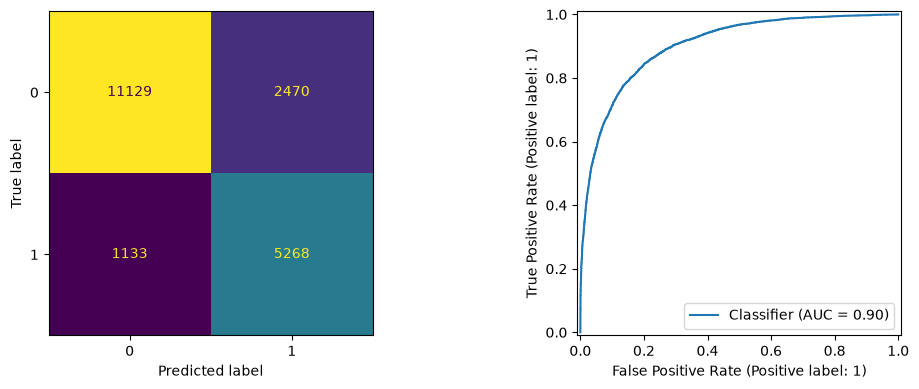

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1])
plt.tight_layout(); plt.show()

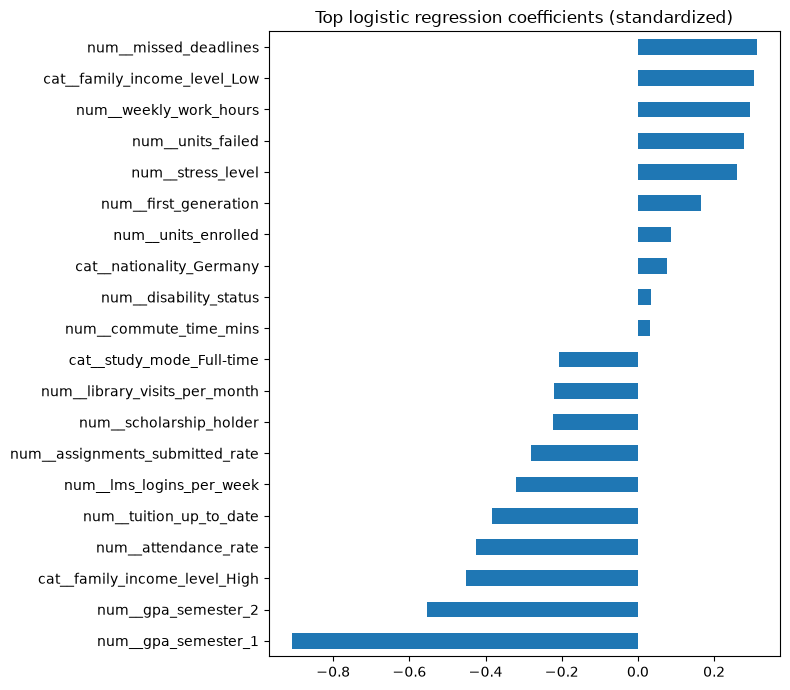

In [7]:
import pandas as pd
names = log_reg.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps['clf'].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot.barh(figsize=(8, 7), title='Top logistic regression coefficients (standardized)')
plt.tight_layout(); plt.show()

In [8]:
coef_df = pd.DataFrame({
    'feature': names,
    'coefficient': log_reg.named_steps['clf'].coef_[0],
})
coef_df['odds_ratio'] = np.exp(coef_df['coefficient'])
coef_df = coef_df.reindex(coef_df['coefficient'].abs().sort_values(ascending=False).index).reset_index(drop=True)
print('Intercept:', log_reg.named_steps['clf'].intercept_[0])
with pd.option_context('display.max_rows', None):
    display(coef_df)

Intercept: -0.2566381089789475


,feature,coefficient,odds_ratio
0,num__gpa_semester_1,-0.908150,0.403270
1,num__gpa_semester_2,-0.553186,0.575115
2,cat__family_income_level_High,-0.452083,0.636301
3,num__attendance_rate,-0.424830,0.653881
4,num__tuition_up_to_date,-0.383312,0.681600
5,num__lms_logins_per_week,-0.320380,0.725873
6,num__missed_deadlines,0.311989,1.366140
7,cat__family_income_level_Low,0.304710,1.356231
8,num__weekly_work_hours,0.294266,1.342142
9,num__assignments_submitted_rate,-0.279727,0.755990
